# STATE Codex r1 — 04 Effect, cell-count and dose controls

**Run All executes the complete source → input features → released-score metrics → condition-level analysis → curves chain.** The four notebooks share source downloads, but default Run All **recalculates** derived features, released-score errors and all analyses even if computed tables exist. Original public inputs are downloaded if absent and checksum verified before reuse. The separate pipeline CLI offers `--reuse-computed` only for deliberately requested receipt-verified reuse; these notebook defaults do not use it. A cold run requires the documented environment, network access, disk space and CPU time; execute on exxact05 for this reconstruction.

The model outputs are the original released STATE predictions. Recomputing their per-condition full-feature log2-fold-change RMSE requires no new neural inference. Archived five-context means and fitted summaries are comparison targets only; they do not enter the calculations below.

Surviving original methods are preserved byte-for-byte. Continuation methods are reconstructed from the original report and native commands. The declared bootstrap seed, axis-standardization population and quintile-matching implementation are recorded explicitly; they were not selected by fitting the historical answers. See [method details](../methods/METHODS.md), [source manifest](../methods/sources.json), [pipeline](../methods/run_pipeline.py), and [original report](../recovery/original_handoff/REPORT.md).

## 1. Data acquisition

Controls use the same verified original released predicted/observed DE rows and Tahoe metadata as the three candidate analyses. Baseline input-side candidate screens also use the original untreated-cell metadata. This notebook recalculates the shared chain, then inspects actual per-condition controls and their fitted sensitivities.

In [1]:
from pathlib import Path
import importlib.util, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, JSON
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'methods/sources.json').is_file())
spec=importlib.util.spec_from_file_location('state_notebook_workflow',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
INPUTS=ROOT/'inputs'
FEATURES=ROOT/'computed/features'
ANALYSIS=ROOT/'computed/analysis'
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)
source_manifest=json.loads((ROOT/'methods/sources.json').read_text())
source_rows=pd.DataFrame(source_manifest['inputs']).drop_duplicates('path')
display(source_rows[['path','bytes','sha256','url']])
print('Unique public source files:',len(source_rows))
print('Declared source bytes:',int(source_rows.bytes.sum()))
print('Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.')


,path,bytes,sha256,url
0,acquisition/DepMap_Model_23Q4.csv,530469,6b77a73209ce3faaa7442dbd947d8e08ddcb08b538c36fe820163f9cff321341,https://ndownloader.figshare.com/files/43746708
1,acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv,449782440,d8e6eb9152c164e9bae49741fd46f5d4fd14c0d298c2a6de5d0996cb6cd3a6f8,https://ndownloader.figshare.com/files/43347204
2,acquisition/cmp_rnaseq_all_20220624.zip,940707972,2af6fd33a16c5c3d48a8d78976f54b4a09fcf0bac4102317b621f24d7bdca39a,https://cog.sanger.ac.uk/cmp/download/rnaseq_all_20220624.zip
3,acquisition/tahoe_obs_metadata.parquet,2293981573,e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe,https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b00654...
4,acquisition/state_tahoe_cell_type_onehot_map_verified.pkl,517889,44bbc9823979ec02a336d62651cf6918e3f6ce162e20b42f86eb06d7e872e20a,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
5,acquisition/official_scores_st_se/C32_pred_de.csv,388384053,7169a2f135657b9f1db7440a9c7feef3f759428b0783f4fc89ac1c48ccac4d76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
6,acquisition/official_scores_st_se/C32_results.csv,468674,cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
7,acquisition/official_scores_st_se/C32_agg_results.csv,3547,5a88c0744b9d31bfa73dcbcbe2d3366b7779f3e334d3a74be0bc7d6a8a53ca76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
8,acquisition/official_scores/C32_real_de.csv,387383572,19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
9,acquisition/official_scores_st_se/HOP62_pred_de.csv,393288407,5db83d0ef3c96cbcfc9f61dd1e851e5e4f2661a22fe831638e80741036ecc594,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...


Unique public source files: 55
Declared source bytes: 11545305551
Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.


## 2. Processing

The scorer computes identity-reference RMSE (true perturbation magnitude), observed FDR-based DE counts and observed cell counts. The original rule uses full-QC cell counts when positive and falls back to all observed cells when there are zero full-QC cells. Target parsing, compound hashing and complete-panel eligibility are shared with the main analyses.

In [2]:
# Actual source acquisition / verification, input processing, released-score reduction,
# condition-level regressions and curves, even when derived outputs already exist.
wf.run_pipeline(ROOT)
wf.show_receipts(ROOT)
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['extract_cell_counts','compute_lfc_scores'])
wf.source_functions(ROOT,'methods/reconstruct.py',['build_condition_table'])
conditions=wf.read_csv(ROOT,'computed/analysis/distance/per_condition_scores.csv')
wf.show_conditions(conditions)


Recalculating source → features → released-score metrics → analysis. Existing source downloads are checksum verified before reuse.
Running download_inputs.py


{"event": "start", "files": 55, "bytes": 11545305551, "destination": "/ewsc/yektefai/spectra_runs/state_codex_r1_reconstruction_20261109/inputs"}
{"event": "verified", "completed": 1, "path": "acquisition/DepMap_Model_23Q4.csv", "bytes": 530469}
{"event": "verified", "completed": 2, "path": "acquisition/state_tahoe_cell_type_onehot_map_verified.pkl", "bytes": 517889}


{"event": "verified", "completed": 3, "path": "acquisition/official_scores_st_se/C32_pred_de.csv", "bytes": 388384053}
{"event": "verified", "completed": 4, "path": "acquisition/official_scores_st_se/C32_results.csv", "bytes": 468674}
{"event": "verified", "completed": 5, "path": "acquisition/official_scores_st_se/C32_agg_results.csv", "bytes": 3547}
{"event": "verified", "completed": 6, "path": "acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv", "bytes": 449782440}


{"event": "verified", "completed": 7, "path": "acquisition/official_scores/C32_real_de.csv", "bytes": 387383572}
{"event": "verified", "completed": 8, "path": "acquisition/official_scores_st_se/HOP62_results.csv", "bytes": 463111}
{"event": "verified", "completed": 9, "path": "acquisition/official_scores_st_se/HOP62_agg_results.csv", "bytes": 3526}
{"event": "verified", "completed": 10, "path": "acquisition/official_scores_st_se/HOP62_pred_de.csv", "bytes": 393288407}


{"event": "verified", "completed": 11, "path": "acquisition/official_scores_st_se/HepG2-C3A_pred_de.csv", "bytes": 385102563}
{"event": "verified", "completed": 12, "path": "acquisition/official_scores/HOP62_real_de.csv", "bytes": 395844167}
{"event": "verified", "completed": 13, "path": "acquisition/official_scores_st_se/HepG2-C3A_agg_results.csv", "bytes": 3591}
{"event": "verified", "completed": 14, "path": "acquisition/official_scores_st_se/HepG2-C3A_results.csv", "bytes": 473841}


{"event": "verified", "completed": 15, "path": "acquisition/official_scores_st_se/Hs 766T_pred_de.csv", "bytes": 390361943}
{"event": "verified", "completed": 16, "path": "acquisition/official_scores_st_se/Hs 766T_results.csv", "bytes": 468068}
{"event": "verified", "completed": 17, "path": "acquisition/official_scores_st_se/Hs 766T_agg_results.csv", "bytes": 3534}
{"event": "verified", "completed": 18, "path": "acquisition/official_scores/HepG2-C3A_real_de.csv", "bytes": 381547673}


... (44 outputs left out)

def build_condition_table(scores_dir,real_dir,cell_counts,axis,*,axis_z_scope,scored_rows=None):
    """Original04 score+eligibility joins; explicit continuation z convention.

    scores_dir supplies <context>_pred_de.csv and _results.csv; real_dir
    supplies _real_de.csv. Reuse of HVG observed rows is supported by final
    integrity_checks.json, but callers must verify those hashes beforehand.
    axis requires cell_line, axis_value. Cell counts require target,
    cell_line,n_cells_full,n_cells_all (original.extract_cell_counts).
    """
    m=original_scoring();scores_dir=Path(scores_dir);real_dir=Path(real_dir)
    axis=pd.read_csv(axis) if isinstance(axis,(str,Path)) else axis.copy()
    counts=pd.read_csv(cell_counts) if isinstance(cell_counts,(str,Path)) else cell_counts.copy()
    if scored_rows is None:scored_rows=score_released_outputs(scores_dir,real_dir)
    all_rows=scored_rows.merge(axis,on='cell_line',validate='many_to_one')
    if len(all_rows)!=len(scored_rows):raise ValueError('Axis merge discarded released rows')
    all_rows=all_rows.merge(counts,on=['cell_line','target'],how='left',validate='one_to_one')
    parsed=all_rows.target.map(m.parse_target)
    all_rows['compound_name']=parsed.map(lambda x:x[0]);all_rows['dose']=parsed.map(lambda x:x[1]);all_rows['dose_unit']=parsed.map(lambda x:x[2])
    all_rows['compound']=all_rows.compound_name.map(m.normalize_compound)
    all_rows['partition']=all_rows.compound.map(m.partition_for)
    all_rows['n_cells']=all_rows.n_cells_full.where(all_rows.n_cells_full>0,all_rows.n_cells_all)
    all_rows['log_n_cells']=np.log1p(all_rows.n_cells);all_rows['log_n_de']=np.log1p(all_rows.n_de)
    coverage=all_rows.groupby('target').cell_line.nunique()
    common=all_rows.loc[all_rows.target.isin(coverage[coverage==5].index)].copy()
    eligibility=common.groupby('compound').agg(n_contexts=('cell_line','nunique'),n_doses=('dose','nunique'),n_targets=('target','nunique'),partition=('partition','first'))
    eligible=eligibility.index[(eligibility.n_contexts==5)&(eligibility.n_doses>=2)]
    common=common.loc[common.compound.isin(eligible)].copy()
    if common.n_cells.isna().any():raise ValueError('Missing original condition cell counts')
    populations={'all_rows':all_rows,'eligible_all':common,'confirmation':common.loc[common.partition=='confirmation'],'contexts':axis}
    if axis_z_scope not in populations:raise ValueError('axis_z_scope must explicitly be all_rows, eligible_all, confirmation, or contexts')
    values=populations[axis_z_scope].axis_value
    mu,sd=values.mean(),values.std(ddof=1)
    if not np.isfinite(sd) or sd<=0:raise ValueError('Degenerate axis')
    common['distance_z']=(common.axis_value-mu)/sd
    common.attrs['axis_standardization']={'scope':axis_z_scope,'mean':float(mu),'sample_sd':float(sd)}
    return common,eligibility,all_rows

,target,cell_line,compound,partition,dose,axis_value,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",C32,rverapamilhydrochloride,discovery,0.05,1.254312,1.956152,1.743597,320,2095
1,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",C32,rverapamilhydrochloride,discovery,0.50,1.254312,2.236865,2.060241,427,1077
2,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",C32,rverapamilhydrochloride,discovery,5.00,1.254312,1.716199,1.415155,531,4029
3,"[('(S)-Crizotinib', 0.05, 'uM')]",C32,scrizotinib,confirmation,0.05,1.254312,1.947983,1.950492,526,1835
4,"[('(S)-Crizotinib', 0.5, 'uM')]",C32,scrizotinib,confirmation,0.50,1.254312,2.034995,2.000006,220,1347
5,"[('(S)-Crizotinib', 5.0, 'uM')]",C32,scrizotinib,confirmation,5.00,1.254312,2.173920,2.117408,283,964
6,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.05,1.254312,2.204911,2.079753,306,1139
7,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.50,1.254312,2.301442,2.134732,341,875
8,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",C32,18glycyrrhetinicacid,discovery,5.00,1.254312,1.907020,1.683020,310,2474
9,"[('4EGI-1', 0.05, 'uM')]",C32,4egi1,discovery,0.05,1.254312,2.272496,1.918225,489,1380


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


Every displayed observation is a real context × released drug-dose target, not an expanded aggregate mean.


## 3. Axis

Identity RMSE, log1p DE count and log1p observed cell count are controls/re-attribution variables, not relabeled input-side failure axes. Baseline candidate screens are reconstructed from the measured metadata and the discovery outcome partition; their diagnostic results are displayed separately.

,cell_line,target,identity_lfc_rmse,n_de,log_n_de,n_cells_full,n_cells_all,n_cells,log_n_cells
0,C32,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",1.743597,320,5.771441,2095,2180,2095,7.647786
1,C32,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",2.060241,427,6.059123,1077,1233,1077,6.982863
2,C32,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",1.415155,531,6.276643,4029,4124,4029,8.301522
3,C32,"[('(S)-Crizotinib', 0.05, 'uM')]",1.950492,526,6.267201,1835,1974,1835,7.515345
4,C32,"[('(S)-Crizotinib', 0.5, 'uM')]",2.000006,220,5.398163,1347,1445,1347,7.206377
5,C32,"[('(S)-Crizotinib', 5.0, 'uM')]",2.117408,283,5.648974,964,1015,964,6.872128
6,C32,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",2.079753,306,5.726848,1139,1234,1139,7.038784
7,C32,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",2.134732,341,5.834811,875,1011,875,6.775366
8,C32,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",1.683020,310,5.739793,2474,2641,2474,7.813996
9,C32,"[('4EGI-1', 0.05, 'uM')]",1.918225,489,6.194405,1380,1405,1380,7.230563


,axis,partition,rows,targets,compounds,contexts,min_cells,median_cells,max_cells
0,distance,discovery,1660,332,111,5,70,1753.5,14009
1,distance,confirmation,4020,804,268,5,1,1856.5,57193
2,distance,all,5680,1136,379,5,1,1820.0,57193
3,s_phase,discovery,1660,332,111,5,70,1753.5,14009
4,s_phase,confirmation,4020,804,268,5,1,1856.5,57193
5,s_phase,all,5680,1136,379,5,1,1820.0,57193
6,lineage,discovery,1660,332,111,5,70,1753.5,14009
7,lineage,confirmation,4020,804,268,5,1,1856.5,57193
8,lineage,all,5680,1136,379,5,1,1820.0,57193


,feature,n_contexts,spearman_rho,two_sided_p
0,gene_mean,5,0.0,1.000000
1,gene_sd,5,0.5,0.391002
2,tscp_mean,5,0.4,0.504632
3,tscp_sd,5,0.8,0.104088
4,mito_mean,5,0.5,0.391002
5,mito_sd,5,0.7,0.188120
6,S_sd,5,0.9,0.037386
7,G2M_sd,5,0.6,0.284757
8,phase_entropy,5,0.5,0.391002


,cell_line,n_control,gene_mean,gene_sd,tscp_mean,tscp_sd,mito_mean,mito_sd,S_sd,G2M_sd,phase_entropy,state_rmse_discovery
0,C32,51984,1173.221491,515.020145,1804.628886,1059.401979,0.055369,0.021105,0.120724,0.260558,0.692636,2.144800
1,HOP62,78130,1301.124485,571.222305,2071.190567,1202.730614,0.052151,0.022357,0.144538,0.432317,0.866324,2.243302
2,HepG2/C3A,31538,1236.943211,726.508786,2015.089067,1721.784541,0.085650,0.031794,0.202683,0.209631,0.415639,2.187640
3,Hs 766T,60761,1144.577986,690.191656,1883.436102,1926.573884,0.114420,0.033249,0.328889,0.429033,0.727161,2.420001
4,PANC-1,97098,1736.183989,788.348853,2995.698274,2022.147403,0.078437,0.027140,0.244544,0.515227,0.839852,2.344446


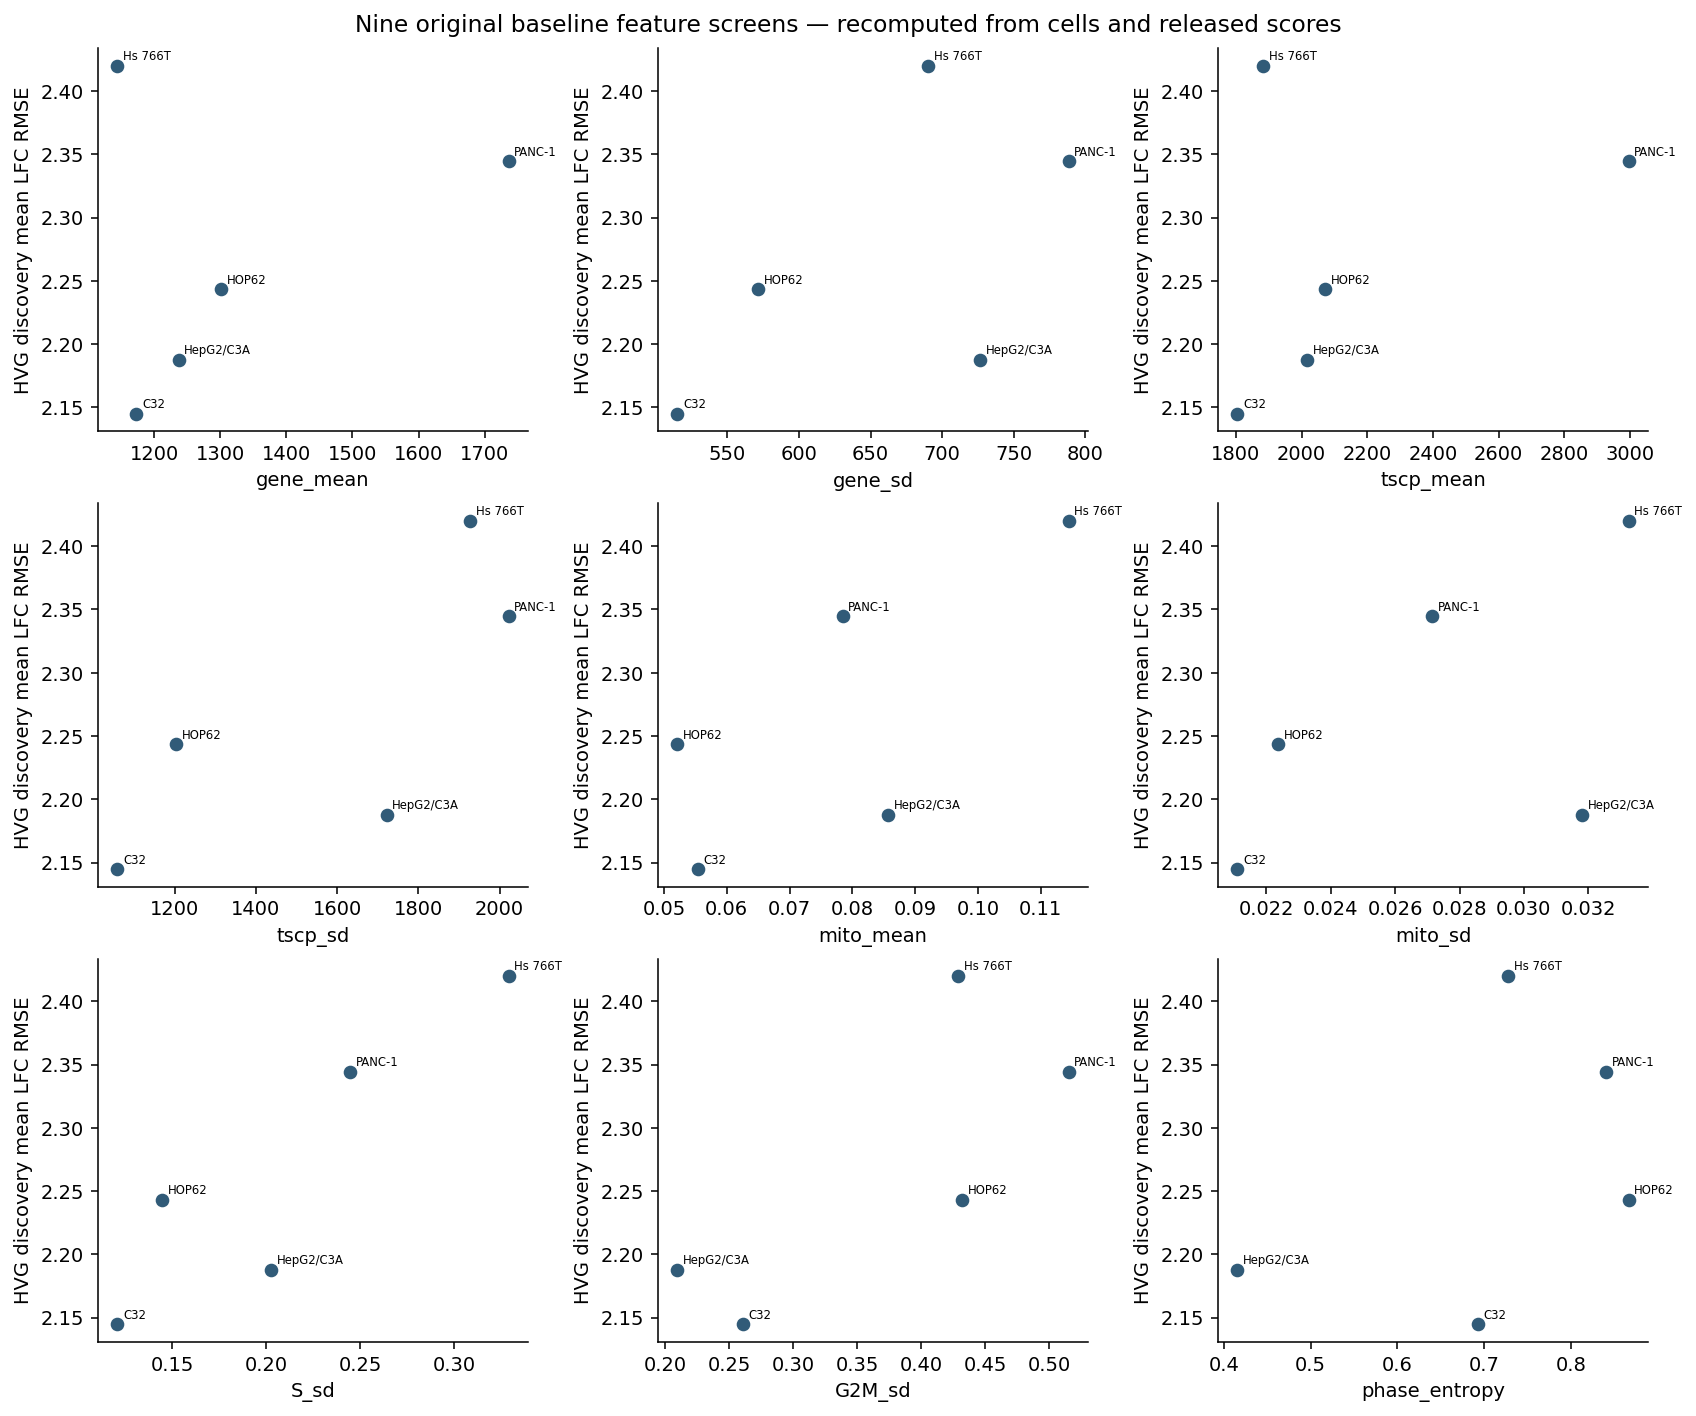

In [3]:
control_columns=['cell_line','target','identity_lfc_rmse','n_de','log_n_de','n_cells_full','n_cells_all','n_cells','log_n_cells']
display(conditions[control_columns].head(12))
counts=wf.read_csv(ROOT,'computed/analysis/controls/source_axis_counts.csv')
screen=wf.read_csv(ROOT,'computed/analysis/controls/baseline_discovery_screen.csv')
display(counts);display(screen)
baseline=wf.read_csv(ROOT,'computed/analysis/controls/baseline_discovery_features.csv')
display(baseline)
import matplotlib.pyplot as plt
feature_names=['gene_mean','gene_sd','tscp_mean','tscp_sd','mito_mean','mito_sd','S_sd','G2M_sd','phase_entropy']
fig,axes=plt.subplots(3,3,figsize=(12,10),layout='constrained')
for ax,feature in zip(axes.flat,feature_names):
    ax.scatter(baseline[feature],baseline.state_rmse_discovery,color='#315b78')
    for row in baseline.itertuples():
        ax.annotate(row.cell_line,(getattr(row,feature),row.state_rmse_discovery),xytext=(3,3),textcoords='offset points',fontsize=6)
    ax.set(xlabel=feature,ylabel='HVG discovery mean LFC RMSE')
    ax.spines[['top','right']].set_visible(False)
fig.suptitle('Nine original baseline feature screens — recomputed from cells and released scores')
wf.show_figure(fig);plt.close(fig)


## 4. Levels and eligibility

Actual sensitivity strata include effect/cell-count quintiles, the three released dose levels, and each held-out-context exclusion. The historically named matching sensitivity uses effect and cell-count quintile indicators in the original within-target regression, preserving all eligible observations. The original saved fit records the eight indicator names; cutpoints within the analysis partition are a declared reconstruction choice. Assignment tables show the actual terms entering the fit.

In [4]:
wf.source_functions(ROOT,'methods/reconstruct.py',['quintile_matching'])
for axis_name in ['distance','s_phase','lineage']:
    display(Markdown('**'+axis_name+' matching support**'))
    strata=wf.read_csv(ROOT,f'computed/analysis/{axis_name}/matching_strata.csv')
    weights=wf.read_csv(ROOT,f'computed/analysis/{axis_name}/matching_weights.csv')
    display(strata)
    print('Matching observations:',len(weights))
    display(weights.head(5))
display(conditions.groupby(['partition','dose']).agg(rows=('target','size'),targets=('target','nunique'),compounds=('compound','nunique')))


**Executed helper:** `methods/reconstruct.py::quintile_matching`

def quintile_matching(frame):
    """Original-style quintile indicator adjustment, historically named matching.

    Recovered control_sensitivities.csv explicitly preserves all4020 rows and
    effect_q_1..4/cells_q_1..4, with no continuous controls in this sensitivity.
    The unrecovered cutpoint scope is declared: qcut within the analyzed
    partition, same boundaries across contexts. No rows are matched/dropped.
    """
    m=original_scoring();c=frame.copy()
    c['effect_quintile'],effect_edges=pd.qcut(c.identity_lfc_rmse,5,labels=False,retbins=True,duplicates='drop')
    c['cell_count_quintile'],cell_edges=pd.qcut(c.n_cells,5,labels=False,retbins=True,duplicates='drop')
    controls=[]
    for prefix,column in [('effect_q','effect_quintile'),('cells_q','cell_count_quintile')]:
        for level in range(1,5):
            name=f'{prefix}_{level}';c[name]=(c[column]==level).astype(float);controls.append(name)
    result=m.fit_within(c,'state_lfc_rmse',controls)
    result.update(status='computed',reconstructed_method=True,
        method='Historical matching sensitivity: eight effect/cell-count quintile indicators in original within-target OLS, retaining every analysis row',
        cutpoint_scope='Within the analyzed partition; shared across contexts; inferred because continuation code is absent',
        effect_quintile_edges=effect_edges.tolist(),cell_count_quintile_edges=cell_edges.tolist())
    table=c.groupby(['effect_quintile','cell_count_quintile','cell_line'],observed=True).size().unstack('cell_line',fill_value=0)
    return result,c,table

**distance matching support**

,effect_quintile,cell_count_quintile,C32,HOP62,HepG2/C3A,Hs 766T,PANC-1
0,0,2,0,0,0,0,1
1,0,3,6,24,20,19,60
2,0,4,37,171,19,149,298
3,1,1,0,0,1,0,0
4,1,2,8,27,42,42,46
5,1,3,80,160,36,102,151
6,1,4,12,47,0,15,35
7,2,0,0,0,2,0,0
8,2,1,9,21,71,40,26
9,2,2,153,130,46,88,74


Matching observations: 4020


,target,overlap_at_N,overlap_at_50,overlap_at_100,overlap_at_200,overlap_at_500,precision_at_N,precision_at_50,precision_at_100,precision_at_200,...,effect_quintile,cell_count_quintile,effect_q_1,effect_q_2,effect_q_3,effect_q_4,cells_q_1,cells_q_2,cells_q_3,cells_q_4
0,"[('(S)-Crizotinib', 0.05, 'uM')]",0.427757,0.04,0.07,0.125,0.416000,0.496599,0.04,0.07,0.125,...,3,2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,"[('(S)-Crizotinib', 0.5, 'uM')]",0.136364,0.10,0.09,0.120,0.136364,0.241379,0.10,0.09,0.120,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,"[('(S)-Crizotinib', 5.0, 'uM')]",0.236749,0.02,0.04,0.150,0.236749,0.339667,0.02,0.04,0.150,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,"[('5-Azacytidine', 0.05, 'uM')]",0.248603,0.08,0.07,0.110,0.248603,0.400691,0.08,0.07,0.110,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,"[('5-Azacytidine', 0.5, 'uM')]",0.357798,0.02,0.06,0.100,0.357798,0.449235,0.02,0.06,0.100,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


... (5 outputs left out)

,effect_quintile,cell_count_quintile,C32,HOP62,HepG2/C3A,Hs 766T,PANC-1
0,0,2,0,0,0,0,1
1,0,3,6,24,20,19,60
2,0,4,37,171,19,149,298
3,1,1,0,0,1,0,0
4,1,2,8,27,42,42,46
5,1,3,80,160,36,102,151
6,1,4,12,47,0,15,35
7,2,0,0,0,2,0,0
8,2,1,9,21,71,40,26
9,2,2,153,130,46,88,74


Matching observations: 4020


,target,overlap_at_N,overlap_at_50,overlap_at_100,overlap_at_200,overlap_at_500,precision_at_N,precision_at_50,precision_at_100,precision_at_200,...,effect_quintile,cell_count_quintile,effect_q_1,effect_q_2,effect_q_3,effect_q_4,cells_q_1,cells_q_2,cells_q_3,cells_q_4
0,"[('(S)-Crizotinib', 0.05, 'uM')]",0.096958,0.00,0.01,0.025,0.086000,0.325355,0.00,0.01,0.025,...,3,2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,"[('(S)-Crizotinib', 0.5, 'uM')]",0.018182,0.00,0.04,0.020,0.018182,0.133659,0.00,0.04,0.020,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,"[('(S)-Crizotinib', 5.0, 'uM')]",0.024735,0.02,0.01,0.030,0.024735,0.176471,0.02,0.01,0.030,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,"[('5-Azacytidine', 0.05, 'uM')]",0.033520,0.00,0.00,0.005,0.033520,0.214131,0.00,0.00,0.005,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,"[('5-Azacytidine', 0.5, 'uM')]",0.048165,0.02,0.01,0.015,0.048165,0.257746,0.02,0.01,0.015,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


rows  targets  compounds
partition    dose                          
confirmation 0.05  1340      268        268
             0.50  1340      268        268
             5.00  1340      268        268
discovery    0.05   555      111        111
             0.50   550      110        110
             5.00   555      111        111

## 5. Model / released scores

The model/reference errors are scored on the same feature rows. Continuous-control models then fit actual condition observations with within-target centering and parent-compound clustered inference. The source below shows the fit, rather than substituting a reported coefficient or inferring a regression from five means.

In [5]:
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['within_design','fit_within'])
wf.source_functions(ROOT,'methods/reconstruct.py',['bootstrap_slopes_fast','analyze_axis'])


**Executed helper:** `methods/original/04_analyze_frozen_axis.py::within_design`

def within_design(frame: pd.DataFrame, outcome: str, controls: list[str]) -> tuple[np.ndarray, np.ndarray, list[str]]:
    names = ["distance_z", *controls]
    work = frame[["target", outcome, *names]].copy()
    for column in names:
        sd = work[column].std(ddof=1)
        if column != "distance_z" and sd > 0:
            work[column] = (work[column] - work[column].mean()) / sd
    centered = work.groupby("target", sort=False)[[outcome, *names]].transform(lambda x: x - x.mean())
    return centered[outcome].to_numpy(float), centered[names].to_numpy(float), names

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::fit_within`

def fit_within(frame: pd.DataFrame, outcome: str, controls: list[str]) -> dict:
    y, x, names = within_design(frame, outcome, controls)
    fit = sm.OLS(y, x).fit(cov_type="cluster", cov_kwds={"groups": frame["compound"].to_numpy()})
    idx = names.index("distance_z")
    estimate = float(fit.params[idx])
    p_two = float(fit.pvalues[idx])
    p_one = p_two / 2 if estimate >= 0 else 1 - p_two / 2
    return {
        "estimate": estimate,
        "se_cluster": float(fit.bse[idx]),
        "p_one_sided": p_one,
        "p_two_sided": p_two,
        "n_rows": len(frame),
        "n_targets": frame["target"].nunique(),
        "n_compounds": frame["compound"].nunique(),
        "controls": controls,
    }

**Executed helper:** `methods/reconstruct.py::bootstrap_slopes_fast`

def bootstrap_slopes_fast(frame,outcome,controls,*,reps,seed,batch_size=512):
    """Same original compound sufficient statistics and multinomial resampling.

    Batched SVD solves reproduce np.linalg.lstsq's default rank threshold;
    batching changes speed, not resampling unit, weighting or random stream.
    """
    m=original_scoring();y,x,names=m.within_design(frame,outcome,controls)
    compounds=frame.compound.to_numpy();unique=np.unique(compounds)
    xtx=np.stack([x[compounds==c].T@x[compounds==c] for c in unique])
    xty=np.stack([x[compounds==c].T@y[compounds==c] for c in unique])
    rng=np.random.default_rng(seed);out=np.empty(reps);idx=names.index('distance_z')
    for start in range(0,reps,batch_size):
        count=min(batch_size,reps-start)
        weights=rng.multinomial(len(unique),np.full(len(unique),1/len(unique)),size=count)
        lhs=np.einsum('bg,gij->bij',weights,xtx,optimize=True)
        rhs=np.einsum('bg,gi->bi',weights,xty,optimize=True)
        # Rank-aware SVD retains the original least-squares behavior if a draw
        # has collinear covariates; a direct solve would fail or amplify noise.
        pinv=np.linalg.pinv(lhs,rcond=np.finfo(float).eps*lhs.shape[-1])
        out[start:start+count]=np.einsum('bij,bj->bi',pinv,rhs)[:,idx]
    return out

**Executed helper:** `methods/reconstruct.py::analyze_axis`

def analyze_axis(conditions,*,seed,reps,partition='confirmation'):
    """Original within-target OLS; paired compound bootstrap per final REPORT.

    No historical seed is claimed for missing continuation scripts. Retain the
    supplied seed/reps in output. No outcome-dependent choices are made here.
    """
    m=original_scoring();c=conditions.copy() if partition=='all' else conditions.loc[conditions.partition==partition].copy()
    if not np.isfinite(c[['distance_z','state_lfc_rmse',*CONTROLS]].to_numpy()).all():raise ValueError('Nonfinite analysis values')
    out={'reconstruction':True,'seed':seed,'bootstrap_reps':reps,'partition':partition,'axis_standardization':conditions.attrs.get('axis_standardization'), 'models':{}}
    draws={}
    for name,y,cov in [('state_raw','state_lfc_rmse',[]),('state_adjusted','state_lfc_rmse',CONTROLS),('identity_raw','identity_lfc_rmse',[])]:
        fit=m.fit_within(c,y,cov)
        # Same seed => identical compound multiplicities, as required by final report.
        draws[name]=bootstrap_slopes_fast(c,y,cov,reps=reps,seed=seed)
        fit['bootstrap_ci95']=np.quantile(draws[name],[.025,.975]).tolist();out['models'][name]=fit
    diff=draws['state_raw']-draws['identity_raw']
    out['paired_state_minus_identity']={'estimate':out['models']['state_raw']['estimate']-out['models']['identity_raw']['estimate'],'ci95':np.quantile(diff,[.025,.975]).tolist()}
    out['dose_sensitivity']={str(dose):m.fit_within(g,'state_lfc_rmse',CONTROLS) for dose,g in c.groupby('dose')}
    out['leave_one_context_out']={cell:m.fit_within(c[c.cell_line!=cell],'state_lfc_rmse',CONTROLS) for cell in sorted(c.cell_line.unique())}
    # Reuse original compound-balanced context SPC helper. ccle_distance is
    # bookkeeping only here and is never an input to the error calculation.
    c['distance']=c.axis_value;c['ccle_distance']=np.nan
    spc=m.context_spc(c,reps,seed)
    from scipy.stats import spearmanr
    out['context_spearman']=float(spearmanr(spc.distance,spc.state_rmse_mean).statistic)
    out['counts']={'rows':len(c),'targets':int(c.target.nunique()),'compounds':int(c.compound.nunique()),'contexts':int(c.cell_line.nunique())}
    return out,spc

## 6. Regressions, curves and controls

The following table contains newly calculated raw/adjusted, matching, dose, exclusion and reference checks across the three analyses. Each estimate traces to the detailed source-built condition table. The plot is rendered from that computed table; it is not a plot of retained original fit summaries.

,axis,partition,kind,subset,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls
0,distance,discovery,dose,0.05,-0.164225,0.009805,1.000000e+00,5.686918e-63,555,111,111,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
1,distance,discovery,dose,0.5,-0.171995,0.009833,1.000000e+00,1.684649e-68,550,110,110,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
2,distance,discovery,dose,5.0,-0.156139,0.009913,1.000000e+00,6.722170e-56,555,111,111,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
3,distance,discovery,leave_one_context_out,C32,-0.153381,0.007653,1.000000e+00,2.345911e-89,1328,332,111,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
4,distance,discovery,leave_one_context_out,HOP62,-0.275727,0.009275,1.000000e+00,3.370503e-194,1328,332,111,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
5,distance,discovery,leave_one_context_out,HepG2/C3A,-0.101553,0.008277,1.000000e+00,1.316292e-34,1328,332,111,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
6,distance,discovery,leave_one_context_out,Hs 766T,-0.094822,0.008650,1.000000e+00,5.800844e-28,1328,332,111,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
7,distance,discovery,leave_one_context_out,PANC-1,-0.172859,0.007015,1.000000e+00,4.404768e-134,1328,332,111,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
8,distance,confirmation,dose,0.05,-0.152905,0.006052,1.000000e+00,8.134430e-141,1340,268,268,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"
9,distance,confirmation,dose,0.5,-0.134063,0.008170,1.000000e+00,1.620053e-60,1340,268,268,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']"


,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95,status,reconstructed_method,method,cutpoint_scope
0,distance / models / state_raw,-0.032213,0.005239,1.000000e+00,7.793156e-10,4020.0,804.0,268.0,[],"[-0.04254994885774676, -0.022016928105237407]",NaN,NaN,NaN,NaN,NaN
1,distance / models / state_adjusted,-0.150035,0.004976,1.000000e+00,9.903387e-200,4020.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[-0.15951551154128896, -0.1398012127844341]",NaN,NaN,NaN,NaN,NaN
2,distance / models / identity_raw,0.163206,0.004507,2.105473e-287,4.210945e-287,4020.0,804.0,268.0,[],"[0.15451658381991967, 0.17208150746334852]",NaN,NaN,NaN,NaN,NaN
3,distance / paired_state_minus_identity,-0.195419,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[-0.20156880125316654, -0.18916182491813147]",NaN,NaN,NaN,NaN
4,distance / dose_sensitivity / 0.05,-0.152905,0.006052,1.000000e+00,8.134430e-141,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
5,distance / dose_sensitivity / 0.5,-0.134063,0.008170,1.000000e+00,1.620053e-60,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
6,distance / dose_sensitivity / 5.0,-0.159950,0.006809,1.000000e+00,4.866489e-122,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
7,distance / leave_one_context_out / C32,-0.128584,0.005732,1.000000e+00,1.811768e-111,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
8,distance / leave_one_context_out / HOP62,-0.269291,0.007472,1.000000e+00,1.887108e-284,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
9,distance / leave_one_context_out / HepG2/C3A,-0.094577,0.004762,1.000000e+00,8.576509e-88,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN


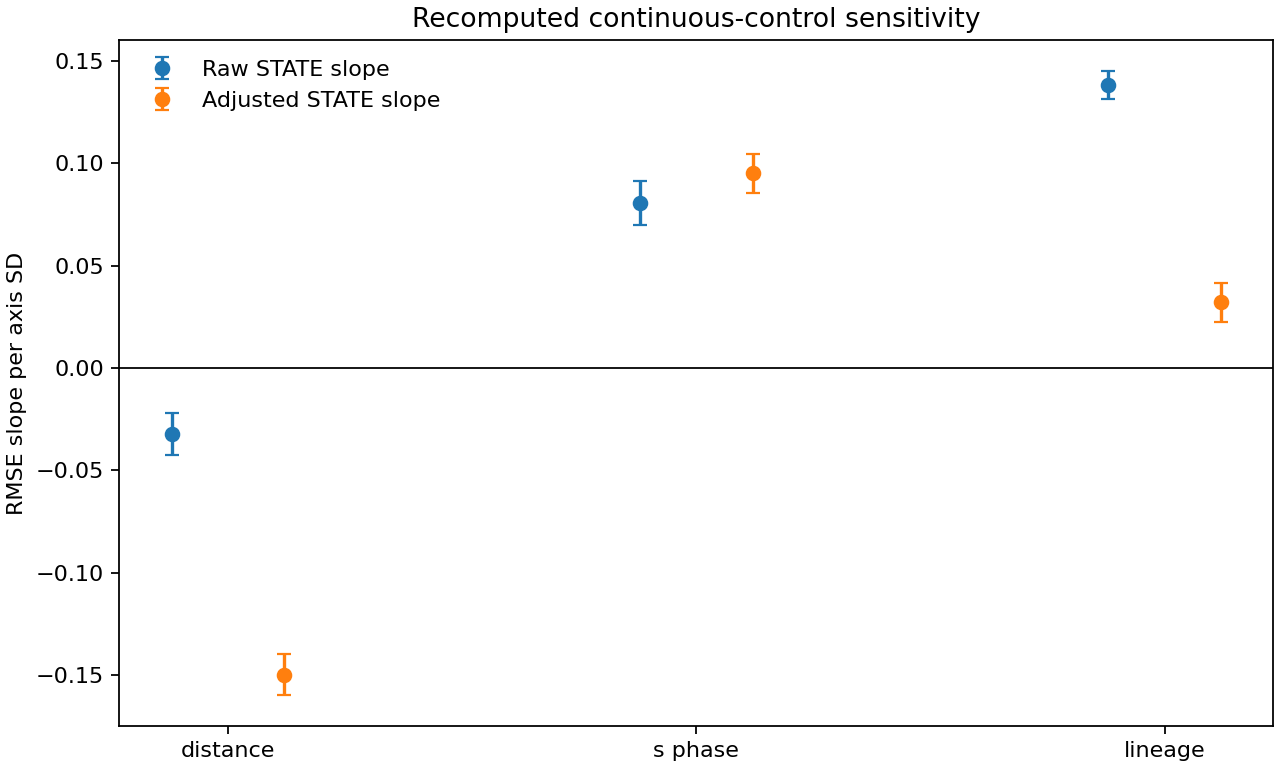

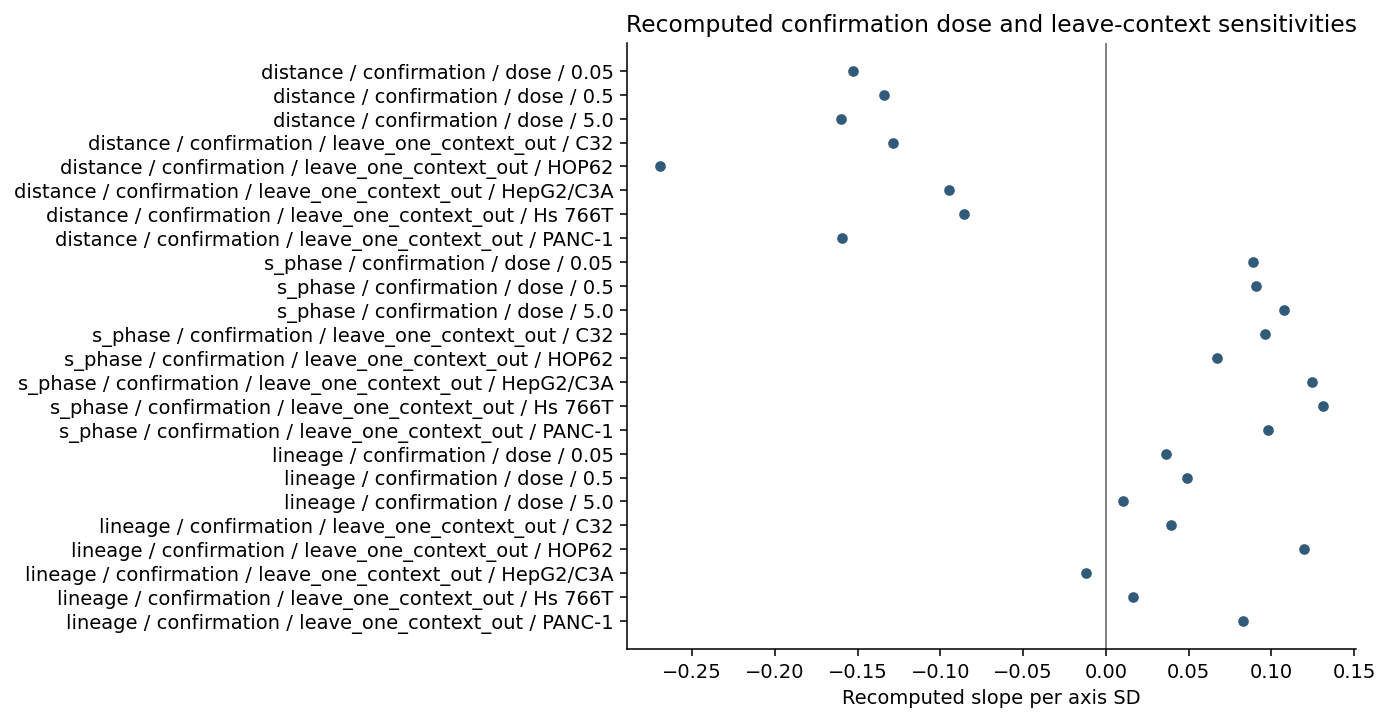

In [6]:
sensitivities=wf.read_csv(ROOT,'computed/analysis/controls/all_sensitivity_estimates.csv')
display(sensitivities)
control_analysis=wf.read_json(ROOT,'computed/analysis/controls/analysis.json')
wf.show_fits(control_analysis['axes'])
wf.show_curve(ROOT,'controls')
sensitivities=sensitivities.loc[sensitivities.partition.eq('confirmation')].copy()
import matplotlib.pyplot as plt
if 'estimate' not in sensitivities: raise ValueError('Calculated sensitivity table lacks estimate')
labels=sensitivities.drop(columns=[c for c in sensitivities if c not in ['axis','partition','kind','subset','analysis','dose','excluded_context','model']]).astype(str).agg(' / '.join,axis=1)
if labels.empty: labels=sensitivities.index.astype(str)
fig,ax=plt.subplots(figsize=(10,max(5,len(sensitivities)*.22)))
ax.scatter(sensitivities.estimate,np.arange(len(sensitivities)),color='#315b78',s=20)
ax.axvline(0,color='gray',linewidth=1)
ax.set(yticks=np.arange(len(sensitivities)),yticklabels=labels,xlabel='Recomputed slope per axis SD',title='Recomputed confirmation dose and leave-context sensitivities')
ax.invert_yaxis();ax.spines[['top','right']].set_visible(False);fig.tight_layout()
wf.show_figure(fig);plt.close(fig)


## 7. Historical result and decision

The original agent used these diagnostics to distinguish a negative distance trend, a strong but non-monotonic S-phase association, and an unstable lineage follow-up. Effect magnitude, DE count, cell count and dose remained controls. The table below compares rebuilt numbers with historical targets without treating those targets as observations.

In [7]:
comparison=wf.historical_comparison(ROOT)
final=wf.read_json(ROOT,'recovery/original_handoff/supporting/results/final_closure_verdict.json')
display(pd.Series(final['primary_candidates'],name='original_agent_decision').to_frame())
print('Historical overall disposition:',final['verdict'])
print('Numerical differences and reconstructed continuation choices remain explicit. No new scientific claim replaces the original determination.')


,axis,metric,historical,recomputed,difference,tolerance,within_tolerance,note
0,distance,state_raw,-0.032210,-0.032213,-3.147093e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
1,distance,state_adjusted,-0.150040,-0.150035,4.982223e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
2,distance,identity_raw,0.163210,0.163206,-4.053477e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
3,distance,quintile_matching,-0.124780,-0.127852,-3.072327e-03,NaN,NaN,Original eight quintile-control columns and full-row inclusion recovered; partition-specific cut...
4,distance,confirmation_rows,4020.000000,4020.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
5,distance,confirmation_targets,804.000000,804.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
6,distance,confirmation_compounds,268.000000,268.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
7,distance,confirmation_contexts,5.000000,5.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
8,s_phase,state_raw,0.080560,0.080561,1.424301e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
9,s_phase,state_adjusted,0.095150,0.095149,-7.615264e-07,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.


Historical values are validation targets only. Differences are reported rather than used to tune inputs or calculations.


,original_agent_decision
basal_transcriptomic_distance,axis_negative_opposite_direction
baseline_s_phase_score_heterogeneity,axis_negative_strong_regression_but_shape_failed
training_lineage_scarcity,axis_negative_unstable_and_not_independently_prospective


Historical overall disposition: CLOSED_NEGATIVE_NO_CERTIFIED_GENERALIZABILITY_FAILURE
Numerical differences and reconstructed continuation choices remain explicit. No new scientific claim replaces the original determination.
